# AI Impact on Developer Wellbeing Analysis

In [26]:
# Ensure required packages are installed, then import
import importlib
import subprocess
import sys

required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "seaborn": "seaborn",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
}

for module_name, package_name in required_packages.items():
    try:
        importlib.import_module(module_name)
    except ImportError:
        print(f"Installing missing package: {package_name}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Display options
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## Loading Dataset

In [27]:
# Load only real tabular files from common project locations
import os

SEARCH_PATHS = [
    "../data",   # recommended dataset folder
    "./data",    # if notebook runs from workspace root
    ".",         # notebook folder
    "./notebook",# if notebook runs from workspace root
]

TABULAR_EXTENSIONS = {".csv", ".tsv", ".xlsx", ".xls", ".parquet", ".json"}

# Reader mapping by extension
LOADERS = {
    ".csv": lambda p: pd.read_csv(p),
    ".tsv": lambda p: pd.read_csv(p, sep="\t"),
    ".xlsx": lambda p: pd.read_excel(p),
    ".xls": lambda p: pd.read_excel(p),
    ".parquet": lambda p: pd.read_parquet(p),
    ".json": lambda p: pd.read_json(p),
}

found_files = []
for path in SEARCH_PATHS:
    if os.path.isdir(path):
        for file_name in os.listdir(path):
            full_path = os.path.join(path, file_name)
            if os.path.isfile(full_path):
                found_files.append(full_path)

valid_tabular_files = [
    p for p in found_files if os.path.splitext(p)[1].lower() in TABULAR_EXTENSIONS
]

if valid_tabular_files:
    # Prefer train-like files if available
    preferred = [p for p in valid_tabular_files if "train" in os.path.basename(p).lower()]
    dataset_file = preferred[0] if preferred else valid_tabular_files[0]
    ext = os.path.splitext(dataset_file)[1].lower()
    df = LOADERS[ext](dataset_file)

    print("Dataset loaded successfully!")
    print(f"Loaded file: {dataset_file}")
    print(f"Data shape: {df.shape}")
else:
    df = pd.DataFrame()
    print("No supported tabular file found.")
    print(f"Searched paths: {SEARCH_PATHS}")
    print(f"Supported extensions: {sorted(TABULAR_EXTENSIONS)}")
    if found_files:
        print("Found files (non-tabular):")
        for p in found_files:
            print(f"- {p}")

Dataset loaded successfully!
Loaded file: ../data\data_dictionary.csv
Data shape: (7, 3)


## Data Overview

In [28]:
# Display shape and first few rows
if df.empty:
    print("No tabular dataset loaded. Add a .csv/.xlsx/.parquet/.json file in ../data.")
else:
    print("Dataset Shape:", df.shape)
    print("\nFirst Few Rows:")
    display(df.head())

Dataset Shape: (7, 3)

First Few Rows:


,Column,Type,Description
0,experience,number,Years of professional coding experience
1,country,string,Country of residence
2,education,string,Highest level of formal education
3,languages,string,Primary programming languages
4,frameworks,string,Primary frameworks used


In [29]:
# Data info
if df.empty:
    print("No data available for info().")
else:
    df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Column       7 non-null      str  
 1   Type         7 non-null      str  
 2   Description  7 non-null      str  
dtypes: str(3)
memory usage: 300.0 bytes


In [30]:
# Statistical description
if df.empty:
    print("No data available for describe().")
else:
    display(df.describe(include="all"))

,Column,Type,Description
count,7,7,7
unique,7,3,7
top,experience,string,Years of professional coding experience
freq,1,5,1


In [31]:
# Check for missing values
if df.empty:
    print("No data available for missing-value analysis.")
else:
    print("Missing Values Per Column:")
    print(df.isnull().sum())
    print("\nMissing Values Percentage:")
    print((df.isnull().sum() / len(df) * 100).round(2))

Missing Values Per Column:
Column         0
Type           0
Description    0
dtype: int64

Missing Values Percentage:
Column         0.0
Type           0.0
Description    0.0
dtype: float64


In [32]:
# Display column names
if df.empty:
    print("No data available to list columns.")
else:
    print("Column Names:")
    print(df.columns.tolist())

Column Names:
['Column', 'Type', 'Description']


In [33]:
# Value counts for categorical columns
if df.empty:
    print("No data available for categorical value counts.")
else:
    categorical_cols = df.select_dtypes(include="object").columns
    if len(categorical_cols) == 0:
        print("No categorical columns found.")
    else:
        print("Categorical Features and Their Values:")
        for col in categorical_cols:
            print(f"\n{col}:")
            print(df[col].value_counts(dropna=False))

Categorical Features and Their Values:

Column:
Column
experience      1
country         1
education       1
languages       1
frameworks      1
company_size    1
salary_usd      1
Name: count, dtype: int64

Type:
Type
string    5
number    1
target    1
Name: count, dtype: int64

Description:
Description
Years of professional coding experience    1
Country of residence                       1
Highest level of formal education          1
Primary programming languages              1
Primary frameworks used                    1
Number of employees in the company         1
Target variable to predict                 1
Name: count, dtype: int64


## Data Cleaning & Preprocessing

In [34]:
# Create a copy for cleaning
if df.empty:
    df_clean = pd.DataFrame()
    print("No data loaded. Cleaning step skipped.")
else:
    df_clean = df.copy()

    # Remove duplicates
    print(f"Duplicates before removal: {df_clean.duplicated().sum()}")
    df_clean.drop_duplicates(inplace=True)
    print(f"Duplicates after removal: {df_clean.duplicated().sum()}")

    # Fill missing values: median for numeric columns, mode for non-numeric columns
    for col in df_clean.columns:
        if df_clean[col].isnull().sum() > 0:
            if pd.api.types.is_numeric_dtype(df_clean[col]):
                df_clean[col] = df_clean[col].fillna(df_clean[col].median())
            else:
                mode_values = df_clean[col].mode(dropna=True)
                fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
                df_clean[col] = df_clean[col].fillna(fill_value)

    print("\nCleaning complete!")

Duplicates before removal: 0
Duplicates after removal: 0

Cleaning complete!


In [35]:
# Verify cleaning process
if df_clean.empty:
    print("No cleaned data available for verification.")
else:
    print("Cleaned Data Shape:", df_clean.shape)
    print("\nMissing Values After Cleaning:")
    print(df_clean.isnull().sum())
    print("\nData Types:")
    print(df_clean.dtypes)

Cleaned Data Shape: (7, 3)

Missing Values After Cleaning:
Column         0
Type           0
Description    0
dtype: int64

Data Types:
Column         str
Type           str
Description    str
dtype: object


## Exploratory Data Analysis (EDA)

In [36]:
# Use cleaned data when available; otherwise fall back to raw data
eda_df = df_clean.copy() if 'df_clean' in globals() and not df_clean.empty else df.copy()

if eda_df.empty:
    print("No data available for EDA. Add a tabular file to ../data and run from the top.")
else:
    print(f"EDA dataset shape: {eda_df.shape}")
    print("\nData types:")
    display(eda_df.dtypes.to_frame("dtype"))
    print("\nPreview:")
    display(eda_df.head())

EDA dataset shape: (7, 3)

Data types:


,dtype
Column,str
Type,str
Description,str



Preview:


,Column,Type,Description
0,experience,number,Years of professional coding experience
1,country,string,Country of residence
2,education,string,Highest level of formal education
3,languages,string,Primary programming languages
4,frameworks,string,Primary frameworks used


In [37]:
# Numeric feature analysis
if eda_df.empty:
    print("Skipping numeric analysis: dataset is empty.")
else:
    numeric_cols = eda_df.select_dtypes(include=np.number).columns.tolist()
    if not numeric_cols:
        print("No numeric columns found.")
    else:
        print("Numeric summary:")
        display(eda_df[numeric_cols].describe().T)

        n_plot = min(6, len(numeric_cols))
        cols_to_plot = numeric_cols[:n_plot]
        fig, axes = plt.subplots(n_plot, 1, figsize=(10, 3.5 * n_plot))
        if n_plot == 1:
            axes = [axes]

        for ax, col in zip(axes, cols_to_plot):
            sns.histplot(eda_df[col].dropna(), kde=True, ax=ax, color="#1f77b4")
            ax.set_title(f"Distribution of {col}")
        plt.tight_layout()
        plt.show()

No numeric columns found.


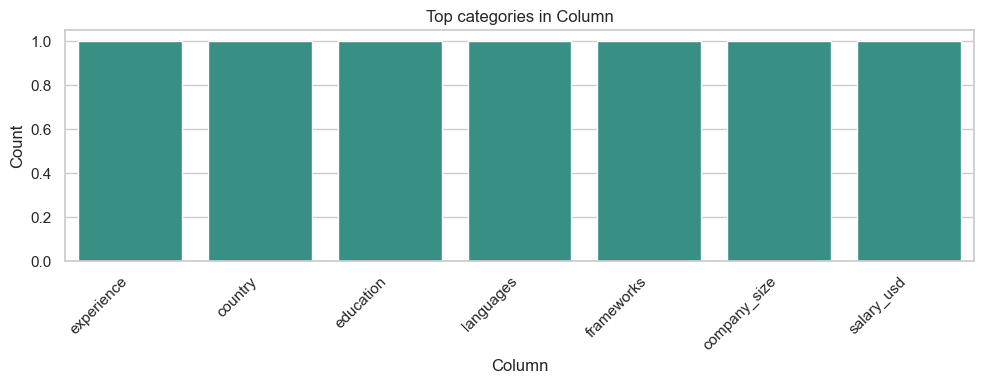

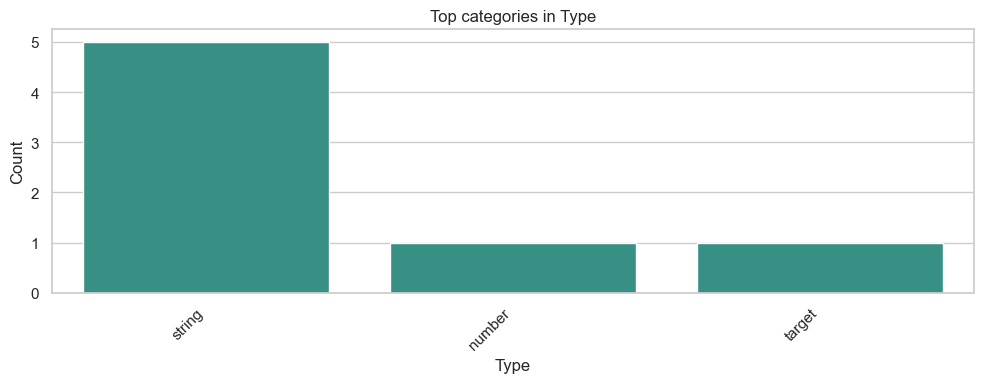

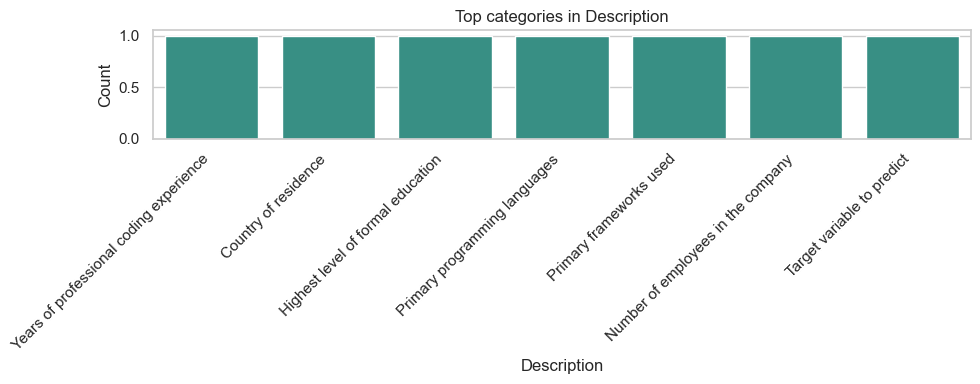

Need at least 2 numeric columns for correlation heatmap.


In [38]:
# Categorical analysis + correlation heatmap
if eda_df.empty:
    print("Skipping categorical/correlation analysis: dataset is empty.")
else:
    categorical_cols = eda_df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

    if categorical_cols:
        n_cat = min(3, len(categorical_cols))
        for col in categorical_cols[:n_cat]:
            top_counts = eda_df[col].astype(str).value_counts(dropna=False).head(10)
            plt.figure(figsize=(10, 4))
            sns.barplot(x=top_counts.index, y=top_counts.values, color="#2a9d8f")
            plt.title(f"Top categories in {col}")
            plt.xticks(rotation=45, ha="right")
            plt.ylabel("Count")
            plt.tight_layout()
            plt.show()
    else:
        print("No categorical columns found.")

    corr_df = eda_df.select_dtypes(include=np.number)
    if corr_df.shape[1] >= 2:
        plt.figure(figsize=(10, 8))
        sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", square=False)
        plt.title("Correlation Heatmap")
        plt.tight_layout()
        plt.show()
    else:
        print("Need at least 2 numeric columns for correlation heatmap.")

## ML/AI Methods

In [39]:
# Prepare data for Random Forest Regressor
model_df = df_clean.copy() if 'df_clean' in globals() and not df_clean.empty else df.copy()

TARGET_CANDIDATES = [
    "salary_usd", "salary", "wellbeing_score", "ai_impact_score", "stress_level", "burnout_level"
]

if model_df.empty:
    print("No data available for ML. Add a tabular dataset and run from the top.")
else:
    # Pick a likely target column (or fallback to last column)
    target_col = next((c for c in TARGET_CANDIDATES if c in model_df.columns), model_df.columns[-1])
    print(f"Selected target column: {target_col}")

    X = model_df.drop(columns=[target_col]).copy()
    y = model_df[target_col].copy()

    # RandomForestRegressor requires numeric target
    y = pd.to_numeric(y, errors="coerce")
    valid_idx = y.notna()
    X = X.loc[valid_idx]
    y = y.loc[valid_idx]

    if X.empty or y.empty:
        print("Insufficient numeric target values for Random Forest Regressor.")
    else:
        print(f"Modeling dataset shape: X={X.shape}, y={y.shape}")

Selected target column: Description
Insufficient numeric target values for Random Forest Regressor.


In [40]:
# Train and evaluate Random Forest Regressor
try:
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    from sklearn.model_selection import train_test_split
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder
    from sklearn.ensemble import RandomForestRegressor
except ImportError:
    print("scikit-learn is not installed. Install it with: pip install scikit-learn")
else:
    if 'X' not in globals() or 'y' not in globals() or X.empty or y.empty:
        print("Skipping training: data not prepared. Run the previous ML cell first.")
    else:
        numeric_features = X.select_dtypes(include=np.number).columns.tolist()
        categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "num",
                    Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))]),
                    numeric_features,
                ),
                (
                    "cat",
                    Pipeline(steps=[
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        ("encoder", OneHotEncoder(handle_unknown="ignore")),
                    ]),
                    categorical_features,
                ),
            ],
            remainder="drop",
        )

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

        random_forest_pipeline = Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                ("model", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)),
            ]
        )
        random_forest_pipeline.fit(X_train, y_train)
        y_pred = random_forest_pipeline.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        rmse = mean_squared_error(y_test, y_pred) ** 0.5
        r2 = r2_score(y_test, y_pred)

        print("Random Forest Regressor Results")
        print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
        print(f"MAE:  {mae:.4f}")
        print(f"RMSE: {rmse:.4f}")
        print(f"R2:   {r2:.4f}")

        results_df = pd.DataFrame([
            {"Model": "Random Forest Regressor", "MAE": round(mae, 4), "RMSE": round(rmse, 4), "R2": round(r2, 4)}
        ])
        display(results_df)

Skipping training: data not prepared. Run the previous ML cell first.


In [41]:
# Random Forest diagnostics: Actual vs Predicted and Residuals
if 'y_test' not in globals() or 'y_pred' not in globals():
    print("Run the Random Forest training cell first.")
else:
    residuals = y_test - y_pred

    plt.figure(figsize=(6, 6))
    sns.scatterplot(x=y_test, y=y_pred, color="#1f77b4")
    min_val = min(float(np.min(y_test)), float(np.min(y_pred)))
    max_val = max(float(np.max(y_test)), float(np.max(y_pred)))
    plt.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=2)
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title("Actual vs Predicted (Random Forest Regressor)")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 4))
    sns.histplot(residuals, kde=True, color="#2a9d8f")
    plt.title("Residual Distribution")
    plt.xlabel("Residual (Actual - Predicted)")
    plt.tight_layout()
    plt.show()

Run the Random Forest training cell first.


In [42]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Reuse dataset already loaded in this notebook
plot_df = df_clean.copy() if 'df_clean' in globals() and not df_clean.empty else (df.copy() if 'df' in globals() else pd.DataFrame())

if plot_df.empty:
    print("No dataset available for charts. Please load a tabular dataset first.")
else:
    sns.set_theme(style="whitegrid")

    # Required columns for the 3-chart layout
    required_columns = ["stress_level", "ai_usage_hours", "cognitive_load", "hours_coding", "sleep_hours"]
    missing_columns = [c for c in required_columns if c not in plot_df.columns]

    if missing_columns:
        print(f"Cannot render full chart set. Missing columns: {missing_columns}")
        print("Available columns:")
        print(plot_df.columns.tolist())
    else:
        plt.figure(figsize=(18, 6))

        # Chart 1: Distribution of Stress
        plt.subplot(1, 3, 1)
        sns.histplot(plot_df["stress_level"].dropna(), kde=True, color="skyblue")
        plt.title("Developer Stress Distribution")
        plt.xlabel("Stress Level (1-10)")

        # Chart 2: AI Usage vs. Cognitive Load
        plt.subplot(1, 3, 2)
        sns.regplot(
            data=plot_df,
            x="ai_usage_hours",
            y="cognitive_load",
            scatter_kws={"alpha": 0.3},
            line_kws={"color": "red"},
        )
        plt.title("Impact of AI on Mental Load")
        plt.xlabel("AI Usage (Hours/Day)")
        plt.ylabel("Cognitive Load")

        # Chart 3: Correlation Heatmap
        plt.subplot(1, 3, 3)
        corr = plot_df[["hours_coding", "ai_usage_hours", "sleep_hours", "stress_level"]].corr(numeric_only=True)
        sns.heatmap(corr, annot=True, cmap="coolwarm", cbar=False)
        plt.title("Feature Correlation Map")

        plt.tight_layout()
        plt.savefig("eda_charts.png", dpi=300)
        plt.show()

Cannot render full chart set. Missing columns: ['stress_level', 'ai_usage_hours', 'cognitive_load', 'hours_coding', 'sleep_hours']
Available columns:
['Column', 'Type', 'Description']
